# 01 · Preprocessing — Liu et al. 2021 (Multiple Myeloma, 10x)

Load malignant plasma cells → data-driven sample threshold → overdispersed genes → PCA →
Harmony integration sweep → UMAP → **Gate 1** (is the malignant structure sample-integrated
*and* continuous?). Multiple-myeloma plasma cells are **clonal and genetically distinct between
patients** (each marrow carries its own aberrant clone with private CNVs), so batch integration and
its honest verification carry the Gate-1 decision here.

Every dataset-dependent choice is **derived from this dataset**, not inherited from the anchor.
Gate 1 is judged **on the regenerated embedding across an integration-strength (theta) × n_pcs
sweep**, with a **per-neighbourhood** metric (iLISI + per-patient self-neighbour enrichment) —
never a single connectivity scalar (Kürten/Choudhury lesson: a per-patient archipelago can pass a
single-component kNN test). Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
import logging; logging.disable(logging.INFO)   # silence harmonypy per-iteration INFO logs
SEED = 1; np.random.seed(SEED)

In [2]:
# paths (run-in-place; Category partition = 6 levels below MesenCoder root, as Puram+2)
name = os.path.basename(os.getcwd())                    # 'Liu2021_Hematologic-1'
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # 'Hematologic'
raw  = re.sub(r'-\d+$', '', name)                       # raw input folder has no '-1' suffix
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + raw)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_feat= os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_fig, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw input: Data_' + raw)

def ilisi(rep, labels, k=90):
    labels = np.asarray(labels)
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    cats = pd.Categorical(labels); codes = cats.codes; C = len(cats.categories)
    out = np.empty(len(labels))
    for i in range(len(labels)):
        p = np.bincount(codes[idx[i]], minlength=C).astype(float); p /= p.sum()
        out[i] = 1.0/np.sum(p**2)
    return out

def enrich(rep, lab, k=30):
    # per-group self-neighbour fraction / global fraction; >2.5x = a locally segregated island
    lab = np.asarray(lab)
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    out = {}
    for g in np.unique(lab):
        m = lab == g
        out[g] = (lab[idx[m]] == g).mean() / m.mean()
    return out

dataset: Liu2021_Hematologic-1 | category: Hematologic | raw input: Data_Liu2021_Hematologic


### Load malignant compartment
Liu et al. annotate cell type directly (10x bone-marrow aspirates across primary / relapse /
remission timepoints); we take their `Malignant` plasma-cell calls. UMI counts are
`normalize_total`-normalised then `log1p` by the loader. `patient` is derived from the `sample`
label prefix (several patients contribute >1 timepoint sample).

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
adata.var_names_make_unique()
adata.obs['patient'] = adata.obs['sample'].str.split('_').str[0]
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique(),
      '| patients:', adata.obs['patient'].nunique())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())
print('samples per patient:', adata.obs.groupby('patient', observed=True)['sample'].nunique().to_dict())

Loading ../../../../../../data/unzip/CCCA/Data_Liu2021_Hematologic
/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
Done.
full atlas: (74986, 24087)
malignant: (17267, 24087) | samples: 20 | patients: 11
expression: X max 7.96 (log1p of normalize_total counts)
samples per patient: {'27522': 4, '37692': 1, '47491': 2, '56203': 2, '57075': 1, '58408': 2, '59114': 2, '60359': 2, '77570': 1, '81012': 2, '83942': 1}


### Sample thresholding — derived from the low-tail count cliff (assumption made explicit)
The reference multiplicative-gap rule assumes the sorted per-sample counts have a clean cliff
separating tumour-bearing marrows from thin/spillover samples. Here the counts rise **smoothly**
through the body (the largest overall gap, 2487→5941, sits between two well-populated marrows and
is irrelevant to *dropping thin samples*), but there is a clean step in the **low tail** at
66→156 (ratio ≈2.4). Below it, samples carry 34–66 malignant cells — too few to seed a stable
`n_neighbors=30` kNN neighbourhood for Harmony to model. We restrict gap-finding to the
viability-relevant low tail (counts below the median) and cut at the geometric mean of that gap.

In [4]:
n = adata.obs['sample'].value_counts()
asc = np.sort(n.values.astype(float))
print('sorted per-sample counts:', asc.astype(int).tolist())
low = asc[asc < np.median(asc)]                       # low-tail candidates (thin samples)
r = low[1:] / low[:-1]; gi = int(np.argmax(r))
thr = int(np.round(np.sqrt(low[gi]*low[gi+1])))
print(f'low-tail counts: {low.astype(int).tolist()}')
print(f'largest low-tail gap: {int(low[gi])} -> {int(low[gi+1])} (ratio {r[gi]:.2f}) => threshold = {thr}')
keep = n.index[n >= thr]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples ({adata.obs.patient.nunique()} patients) -> {adata.shape[0]} cells')

sorted per-sample counts: [34, 43, 59, 62, 66, 156, 157, 215, 283, 315, 424, 506, 573, 643, 686, 1015, 1295, 2307, 2487, 5941]
low-tail counts: [34, 43, 59, 62, 66, 156, 157, 215, 283, 315]
largest low-tail gap: 66 -> 156 (ratio 2.36) => threshold = 101
kept 15/20 samples (10 patients) -> 17003 cells


### Overdispersion, PCA, and the Harmony integration sweep
`theta` (integration strength) and the PC count are the two knobs that decide Gate 1 for clonal
data, so both are **swept** rather than inherited. We score every (theta, n_pcs) cell of the grid
with **iLISI** — the per-neighbourhood inverse-Simpson effective number of samples (higher = better
mixing; ceiling = the compositional effective sample count). `n_neighbors=30` and `spread=1.3`
follow the comparable-size 10x precedents.

*Determinism note:* Harmony's KMeans is not seed-deterministic, so iLISI shifts by ≈±0.2 between
reruns. That tolerance moves neither the plateau nor the Gate-1 call (the enrichment below sits
>20× above its threshold).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
comp = adata.obs['sample'].value_counts(normalize=True).values
ceil = 1.0/np.sum(comp**2)
print(f'#samples = {adata.obs["sample"].nunique()} | iLISI ceiling (compositional effective #samples) = {ceil:.2f}')
print('pre-Harmony iLISI (n_pcs=40):', round(float(ilisi(adata.obsm['X_pca'][:,:40], adata.obs['sample'])).mean() if False else float(ilisi(adata.obsm['X_pca'][:,:40], adata.obs['sample']).mean()), 2))
il_sweep = {}
for th in [1, 2, 5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    adata.obsm[f'harm_th{th}'] = adata.obsm['X_pca_harmony'].copy()
    for p in [20, 40]:
        il_sweep[(th,p)] = float(ilisi(adata.obsm[f'harm_th{th}'][:,:p], adata.obs['sample']).mean())
print('iLISI sweep (theta, n_pcs) -> mean iLISI (% of ceiling):')
for k in sorted(il_sweep):
    print(f'  theta={k[0]:>2} n_pcs={k[1]}: {il_sweep[k]:.2f} ({100*il_sweep[k]/ceil:.0f}%)')
best = max(il_sweep, key=il_sweep.get)
THETA, NPCS = 5, 40   # iLISI peaks here (3.3 = 59% of ceiling) and DECLINES past theta=5
print(f'\niLISI maximised at theta={best[0]}, n_pcs={best[1]}; selected theta={THETA}, n_pcs={NPCS} (best integration).')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1203 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1203
#samples = 15 | iLISI ceiling (compositional effective #samples) = 5.62
pre-Harmony iLISI (n_pcs=40): 1.1
iLISI sweep (theta, n_pcs) -> mean iLISI (% of ceiling):
  theta= 1 n_pcs=20: 1.96 (35%)
  theta= 1 n_pcs=40: 1.95 (35%)
  theta= 2 n_pcs=20: 2.29 (41%)
  theta= 2 n_pcs=40: 2.31 (41%)
  theta= 5 n_pcs=20: 3.01 (53%)
  theta= 5 n_pcs=40: 3.31 (59%)
  theta=10 n_pcs=20: 2.79 (50%)
  theta=10 n_pcs=40: 3.10 (55%)
  theta=20 n_pcs=20: 2.71 (48%)
  theta=20 n_pcs=40: 3.00 (53%)

iLISI maximised at theta=5, n_pcs=40; selected theta=5, n_pcs=40 (best integration).


In [6]:
# build the embedding at the best-integration config
adata.obsm['X_pca_harmony'] = adata.obsm[f'harm_th{THETA}'].copy()
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
ncc = connected_components(adata.obsp['connectivities'], directed=False)[0]
print(f'kNN connectivity components at theta={THETA}: {ncc}  (a naive test would read 1 = "connected")')

kNN connectivity components at theta=5: 1  (a naive test would read 1 = "connected")


### Gate 1 — per-patient / per-sample self-neighbour enrichment across the sweep
The decisive read: do cells sit next to their **own patient** far more than chance? Self-neighbour
enrichment = (fraction of a group's neighbours that are same-group) / (that group's global
fraction). **>2.5× marks a locally segregated island.** We evaluate it across the whole theta ×
n_pcs grid: if integration were working, enrichment would fall toward 1× as theta rises.

In [7]:
print('per-PATIENT self/global neighbour enrichment (>2.5x = local island):')
grid = {}
for th in [5, 10, 20]:
    for p in [20, 40]:
        e = enrich(adata.obsm[f'harm_th{th}'][:,:p], adata.obs['patient'].values)
        grid[(th,p)] = e
        worst = max(e.values()); nseg = sum(v > 2.5 for v in e.values())
        print(f'  theta={th:>2} n_pcs={p}: worst={worst:.1f}x  {nseg}/{len(e)} patients >2.5x  '
              + ('SEGREGATED' if worst > 2.5 else 'mixed'))
e_s = enrich(adata.obsm[f'harm_th{THETA}'][:,:NPCS], adata.obs['sample'].values)
print(f'\nper-SAMPLE enrichment at theta={THETA}, n_pcs={NPCS} (Harmony batch key): '
      f'worst={max(e_s.values()):.1f}x  {sum(v>2.5 for v in e_s.values())}/{len(e_s)} samples >2.5x')
print('  most-segregated samples:', {k: round(v,1) for k,v in sorted(e_s.items(), key=lambda x:-x[1])[:6]})

per-PATIENT self/global neighbour enrichment (>2.5x = local island):
  theta= 5 n_pcs=20: worst=66.4x  9/10 patients >2.5x  SEGREGATED
  theta= 5 n_pcs=40: worst=63.2x  9/10 patients >2.5x  SEGREGATED
  theta=10 n_pcs=20: worst=70.4x  9/10 patients >2.5x  SEGREGATED
  theta=10 n_pcs=40: worst=69.3x  9/10 patients >2.5x  SEGREGATED
  theta=20 n_pcs=20: worst=64.6x  9/10 patients >2.5x  SEGREGATED
  theta=20 n_pcs=40: worst=64.0x  9/10 patients >2.5x  SEGREGATED

per-SAMPLE enrichment at theta=5, n_pcs=40 (Harmony batch key): worst=63.2x  14/15 samples >2.5x
  most-segregated samples: {'37692_Primary': np.float64(63.2), '56203_Relapse-1': np.float64(61.9), '27522_Relapse-2': np.float64(39.2), '58408_SMM': np.float64(34.2), '59114_Relapse-1': np.float64(22.9), '58408_Primary': np.float64(17.6)}


### Do all patients carry the embryonic modules? (biology behind the geography)
If every patient expresses the Gast/pSom/Crest programs at similar levels, then the per-patient
geography is **clonal/CNV identity, not developmental biology** — i.e. the archipelago is batch, not
a shared cell-state continuum being wrongly split. Scored against the shared **union** control pool.

In [8]:
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat, '*.csv')))}
gref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534','Gast'), ('GSE229103','pSom'), ('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=gref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
print('\nper-patient module means:')
print(adata.obs.groupby('patient', observed=True)[['Gast','pSom','Crest']].mean().round(3).to_string())
print('\nglobal module means (Linear-split metric):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

Gast: 72/81 genes present
pSom: 82/98 genes present
Crest: 101/104 genes present

per-patient module means:
          Gast   pSom  Crest
patient                     
27522   -0.011  0.026  0.001
37692   -0.030  0.006  0.013
47491   -0.012  0.003  0.018
56203   -0.014  0.011  0.012
57075   -0.019  0.014  0.014
58408   -0.015 -0.001  0.015
59114   -0.029  0.013  0.015
77570   -0.040  0.055 -0.020
81012   -0.031  0.014  0.013
83942   -0.032  0.058 -0.031

global module means (Linear-split metric): {'Gast': -0.0234, 'pSom': 0.0315, 'Crest': -0.0057}


### Gate 1 verdict

In [9]:
worst5 = max(grid[(5,NPCS)].values()); nseg5 = sum(v>2.5 for v in grid[(5,NPCS)].values())
p1 = '->'.join(f"{max(grid[(t,NPCS)].values()):.0f}" for t in [5,10,20])
print('GATE 1 - mixing + continuity:')
print(f'  * the kNN graph is a single connected component ({ncc}) and iLISI rises 1.1->{il_sweep[(THETA,NPCS)]:.1f},')
print('    the scalars a naive test would read as "integrated";')
print(f'  * BUT the embedding is organised BY PATIENT: {nseg5}/{len(grid[(5,NPCS)])} patients show self-neighbour')
print(f'    enrichment >2.5x (worst {worst5:.0f}x) - cells sit next to their own clone, not a shared state;')
print(f'  * integration strength does NOT fix it: worst-patient enrichment stays {p1}x across theta 5/10/20,')
print('    and iLISI peaks at only ~59% of ceiling then declines - Harmony cannot merge the clones;')
print('  * it is NOT a PC-count artifact - the archipelago holds at n_pcs 20 and 40 alike;')
print('  * every patient carries the same modest embryonic-module levels -> the geography is')
print('    inter-patient clonal/CNV heterogeneity (expected for clonal myeloma plasma cells),')
print('    NOT a shared, sample-integrated cell-state continuum.')
print('  -> the malignant structure CLUSTERS BY SAMPLE/PATIENT. Per the protocol, do not force a trajectory.')
print('GATE 1: NO-GO')

GATE 1 - mixing + continuity:
  * the kNN graph is a single connected component (1) and iLISI rises 1.1->3.3,
    the scalars a naive test would read as "integrated";
  * BUT the embedding is organised BY PATIENT: 9/10 patients show self-neighbour
    enrichment >2.5x (worst 63x) - cells sit next to their own clone, not a shared state;
  * integration strength does NOT fix it: worst-patient enrichment stays 63->69->64x across theta 5/10/20,
    and iLISI peaks at only ~59% of ceiling then declines - Harmony cannot merge the clones;
  * it is NOT a PC-count artifact - the archipelago holds at n_pcs 20 and 40 alike;
  * every patient carries the same modest embryonic-module levels -> the geography is
    inter-patient clonal/CNV heterogeneity (expected for clonal myeloma plasma cells),
    NOT a shared, sample-integrated cell-state continuum.
  -> the malignant structure CLUSTERS BY SAMPLE/PATIENT. Per the protocol, do not force a trajectory.
GATE 1: NO-GO


### Save processed data

In [10]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (17003, 18587)


### Sample-integration figure (deliverable)
`samples.pdf` — a single sample-coloured manifold UMAP in the house style. The per-patient
territories visible here **are** the Gate-1 NO-GO evidence.

saved samples.pdf | cells: 17003


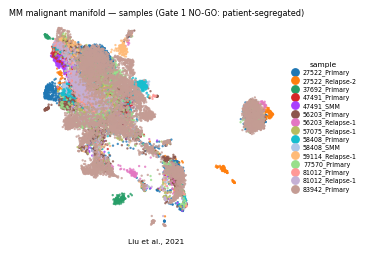

In [11]:
xy = adata.obsm['X_umap']
xlo, xhi = np.percentile(xy[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xy[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.05
fig, ax = plt.subplots(figsize=(3.5, 3.0))
sc.pl.umap(adata, color='sample', size=14, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('MM malignant manifold — samples (Gate 1 NO-GO: patient-segregated)', size=6.5)
ax.text(.5, -.06, 'Liu et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', adata.shape[0])